<a href="https://colab.research.google.com/github/sanjaymj06/Build-and-Deploy/blob/main/EXP%204A%20-%20SUPPORT%20VECTOR%20MACHINES%20(SVM).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================================
# EXPERIMENT NO: 1
# SETTING UP THE ENVIRONMENT AND PREPROCESSING THE DATA
# ==========================================================

# 1. Install necessary libraries (Run only if required)
# !pip install numpy pandas matplotlib seaborn scikit-learn

# 2. Import Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# 3. Load Dataset
df = sns.load_dataset('titanic')

# Display first five rows
print("First Five Rows:")
print(df.head())

# 4. Explore the Dataset
print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

# 5. Handle Missing Values

# Fill missing values in Age with median
df['age'] = df['age'].fillna(df['age'].median())

# Fill missing values in Embark Town with mode
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])

# Drop Deck column because it has many missing values
df.drop(columns=['deck'], inplace=True)

# 6. Encode Categorical Variables

# Label Encoding
le = LabelEncoder()

df['sex'] = le.fit_transform(df['sex'])
df['embark_town'] = le.fit_transform(df['embark_town'])

# Drop unnecessary columns
df.drop(columns=[
    'embarked',
    'class',
    'who',
    'alive',
    'adult_male',
    'alone'
], inplace=True)

# Convert remaining categorical column 'pclass'
df['pclass'] = df['pclass'].astype(int)

# Convert categorical column 'sex'
df['sex'] = df['sex'].astype(int)

# Convert categorical column 'embark_town'
df['embark_town'] = df['embark_town'].astype(int)

# Convert categorical column 'sibsp' and 'parch'
df['sibsp'] = df['sibsp'].astype(int)
df['parch'] = df['parch'].astype(int)

# 7. Feature Scaling

scaler = StandardScaler()

numerical_cols = ['age', 'fare']

df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

# 8. Split Dataset

# Features
X = df.drop('survived', axis=1)

# Target
y = df['survived']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# 9. Display Preprocessed Data

print("\nTraining Data Shape:", X_train.shape)
print("Test Data Shape:", X_test.shape)

print("\nPreprocessed Training Data:")
print(X_train.head())

First Five Rows:
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------

Best Parameters from Grid Search: {'C': 10, 'gamma': 0.01}

=== SVM (RBF) - Test Metrics ===
Accuracy : 0.9825
Precision: 0.9861
Recall   : 0.9861
F1-Score : 0.9861
ROC-AUC  : 0.9977

Confusion Matrix:
[[41  1]
 [ 1 71]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



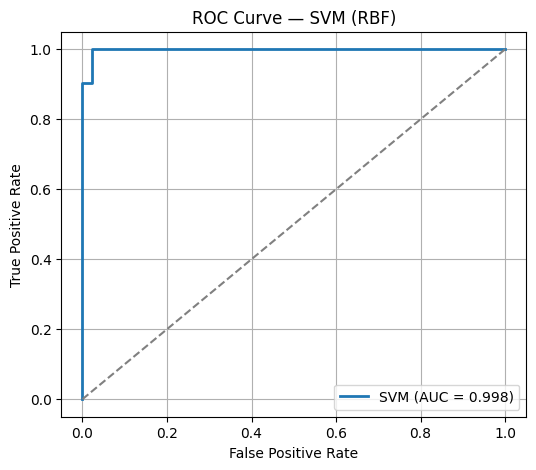

In [1]:
# ==========================================
# EXPERIMENT 4A – SUPPORT VECTOR MACHINE (SVM)
# ==========================================

# 1. Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

# 2. Load Dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")   # 0 = Malignant, 1 = Benign

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 4. Standardize Features
scaler = StandardScaler()

X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# 5. Create SVM Model
svm = SVC(
    kernel='rbf',
    probability=True,
    random_state=42
)

# 6. Hyperparameter Grid
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", 0.01, 0.001, 0.0001]
}

# 7. Grid Search
grid = GridSearchCV(
    estimator=svm,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=0
)

grid.fit(X_train_sc, y_train)

print("Best Parameters from Grid Search:", grid.best_params_)

best_svm = grid.best_estimator_

# 8. Train Final Model
best_svm.fit(X_train_sc, y_train)

# Predictions
y_pred = best_svm.predict(X_test_sc)
y_prob = best_svm.predict_proba(X_test_sc)[:, 1]

# 9. Evaluation Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
cm = confusion_matrix(y_test, y_pred)

print("\n=== SVM (RBF) - Test Metrics ===")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")
print(f"ROC-AUC  : {auc:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 10. ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, linewidth=2, label=f"SVM (AUC = {auc:.3f})")
plt.plot([0,1], [0,1], '--', color='gray')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — SVM (RBF)")
plt.legend()
plt.grid(True)

plt.show()

First Five Samples:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

SVM Accuracy: 0.9777777777777777
SVM Confusion Matrix:
[[19  0  0]
 [ 0 12  1]
 [ 0  0 13]]

Random Forest Accuracy: 1.0
Random Forest Confusion Matrix:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]


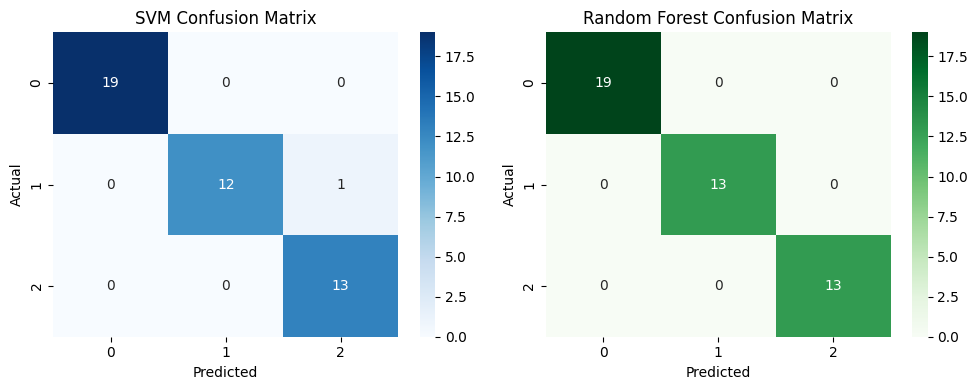

In [ ]:
# ==========================================================
# EXPERIMENT NO: 2
# SUPPORT VECTOR MACHINE (SVM) AND RANDOM FOREST
# FOR BINARY & MULTICLASS CLASSIFICATION
# ==========================================================

# 1. Import Libraries
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 2. Load Dataset
iris = load_iris()

X = iris.data
y = iris.target

# Display first five samples
print("First Five Samples:")
print(pd.DataFrame(X, columns=iris.feature_names).head())

# 3. Feature Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.30,
    random_state=42
)

# ==========================================================
# PART A: SUPPORT VECTOR MACHINE (SVM)
# ==========================================================

# 5. Initialize SVM Model
svm_model = SVC(kernel='linear')

# 6. Train SVM Model
svm_model.fit(X_train, y_train)

# Predict using SVM
y_pred_svm = svm_model.predict(X_test)

# Evaluate SVM
print("\nSVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("SVM Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

# ==========================================================
# PART B: RANDOM FOREST
# ==========================================================

# 7. Initialize Random Forest Model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train Random Forest Model
rf_model.fit(X_train, y_train)

# Predict using Random Forest
y_pred_rf = rf_model.predict(X_test)

# Evaluate Random Forest
print("\nRandom Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Random Forest Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

# ==========================================================
# VISUALIZE CONFUSION MATRICES
# ==========================================================

plt.figure(figsize=(10,4))

# SVM Confusion Matrix
plt.subplot(1,2,1)
sns.heatmap(
    confusion_matrix(y_test, y_pred_svm),
    annot=True,
    fmt='d',
    cmap='Blues'
)
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

# Random Forest Confusion Matrix
plt.subplot(1,2,2)
sns.heatmap(
    confusion_matrix(y_test, y_pred_rf),
    annot=True,
    fmt='d',
    cmap='Greens'
)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

First Five Samples:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]

Confusion Matrix:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]

Accuracy Score: 1.0


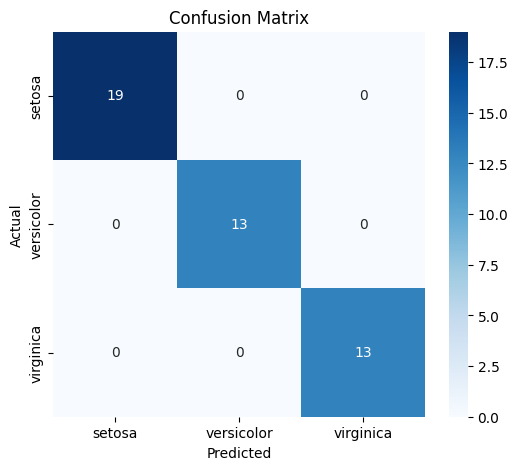

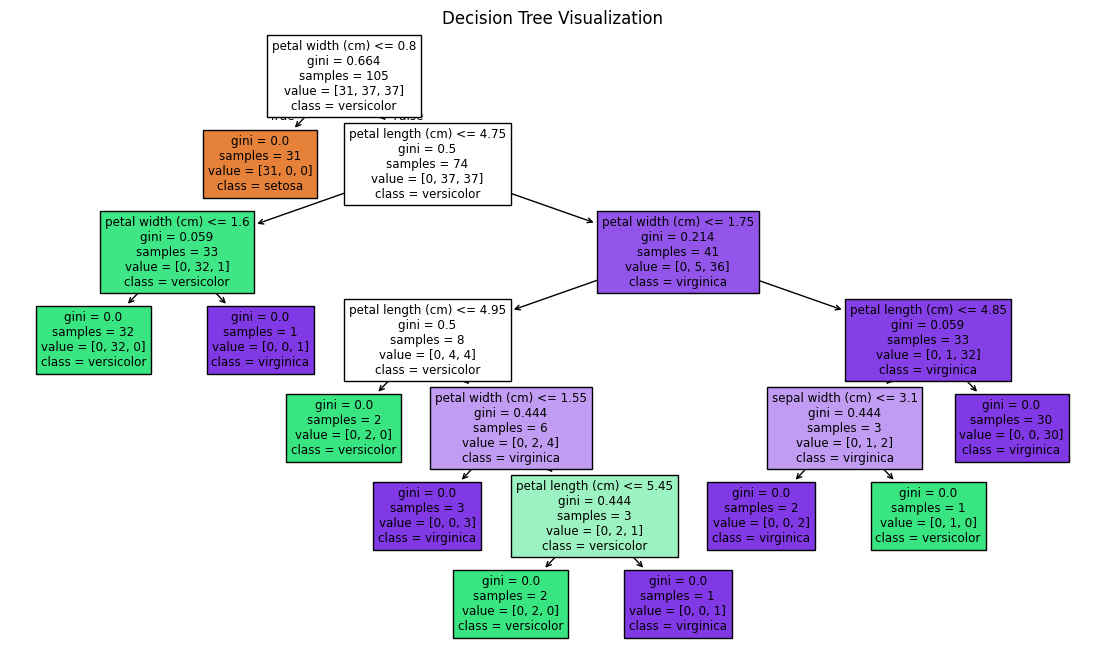

In [ ]:
# ==========================================================
# EXPERIMENT NO: 3
# CLASSIFICATION WITH DECISION TREES
# ==========================================================

# Step 1: Import Libraries
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# Step 2: Load Dataset
iris = load_iris()

X = iris.data
y = iris.target

# Display first five samples
print("First Five Samples:")
print(X[:5])

# Step 3: Split the Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

# Step 4: Train the Decision Tree Classifier
dt_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=0
)

dt_model.fit(X_train, y_train)

# Step 5: Predict
y_pred = dt_model.predict(X_test)

# Step 6: Evaluate the Model
cm = confusion_matrix(y_test, y_pred)
acc = accuracy_score(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

print("\nAccuracy Score:", acc)

# Step 7: Visualize Confusion Matrix
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    cmap="Blues",
    fmt='d',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Step 8: Visualize the Decision Tree
plt.figure(figsize=(14,8))

plot_tree(
    dt_model,
    filled=True,
    feature_names=iris.feature_names,
    class_names=iris.target_names
)

plt.title("Decision Tree Visualization")
plt.show()